# 02 · Linear regression: OLS, Ridge, Lasso, Elastic Net

Linear models predict $\hat y = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$. They are fast, interpretable, hard to overfit once regularised,
and they **extrapolate**, which trees cannot. On noisy problems (finance, small samples) a well-regularised linear model is often the model to beat.

| Model | Minimises | Effect |
|---|---|---|
| **OLS** | $\sum (y - X\beta)^2$ | unbiased, but high variance when features are many/correlated |
| **Ridge** (L2) | $\sum (y - X\beta)^2 + \alpha \sum \beta_j^2$ | shrinks all coefficients toward 0; great with correlated features |
| **Lasso** (L1) | $\tfrac{1}{2n}\sum (y - X\beta)^2 + \alpha \sum \lvert\beta_j\rvert$ | sets some coefficients exactly to 0 → feature selection |
| **Elastic Net** | mix of L1 and L2 | sparse like Lasso but stable with correlated groups |

**Always standardise features before Ridge/Lasso**: the penalty treats all coefficients equally, so it should see them on the same scale.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

## 1. OLS with statsmodels — the "statistics" view

`statsmodels` gives standard errors, t-stats and p-values, useful for *inference* (is this effect real?).
`sklearn` is for *prediction* (pipelines, CV). Same coefficients either way.

Data: the **diabetes** dataset (442 patients, 10 standardised baseline measurements, target = disease progression after one year).

In [2]:
import statsmodels.api as sm
from sklearn.datasets import load_diabetes

X, y = load_diabetes(return_X_y=True, as_frame=True)
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(f"R² = {ols.rsquared:.3f}, adj. R² = {ols.rsquared_adj:.3f}")
print(ols.summary().tables[1])

R² = 0.518, adj. R² = 0.507
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.1335      2.576     59.061      0.000     147.071     157.196
age          -10.0099     59.749     -0.168      0.867    -127.446     107.426
sex         -239.8156     61.222     -3.917      0.000    -360.147    -119.484
bmi          519.8459     66.533      7.813      0.000     389.076     650.616
bp           324.3846     65.422      4.958      0.000     195.799     452.970
s1          -792.1756    416.680     -1.901      0.058   -1611.153      26.802
s2           476.7390    339.030      1.406      0.160    -189.620    1143.098
s3           101.0433    212.531      0.475      0.635    -316.684     518.770
s4           177.0632    161.476      1.097      0.273    -140.315     494.441
s5           751.2737    171.900      4.370      0.000     413.407    1089.140
s6            67.6267   

How to read it: `coef` is the change in $y$ per unit change in $x$ *holding the others fixed*; `P>|t|` tests whether it's zero.
Note `s1` and `s2` (two cholesterol measures): large opposite-signed coefficients with huge standard errors. That's **multicollinearity**: the features are highly correlated, so OLS can't pin down how to split credit between them. Ridge fixes exactly this.

OLS assumptions worth checking: linear relationship, errors with constant variance (else use robust SEs: `fit(cov_type="HC3")`), independent errors (else clustered / HAC SEs for time series), no perfect collinearity.

In [3]:
print(X[["s1", "s2"]].corr().round(2))

     s1   s2
s1  1.0  0.9
s2  0.9  1.0


## 2. When OLS breaks: many features, little data

Simulate 120 training rows with 80 weakly-informative features. OLS fits the training noise; Ridge and Lasso trade a little bias for a big cut in variance.

In [4]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

p = 80
beta = rng.normal(scale=0.3, size=p)
def simulate(n):
    Xs = rng.normal(size=(n, p))
    return Xs, Xs @ beta + rng.normal(scale=2, size=n)

Xs_tr, ys_tr = simulate(120)
Xs_te, ys_te = simulate(5000)

alphas = np.logspace(-3, 3, 50)
models = {
    "OLS": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED)),
    "ElasticNet": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .5, .9], cv=5, random_state=SEED)),
}
for name, m in models.items():
    m.fit(Xs_tr, ys_tr)
    print(f"{name:>10}: train R² {r2_score(ys_tr, m.predict(Xs_tr)):5.2f} | test R² {r2_score(ys_te, m.predict(Xs_te)):5.2f}")

       OLS: train R²  0.84 | test R² -1.63
     Ridge: train R²  0.61 | test R²  0.24


     Lasso: train R²  0.46 | test R²  0.15


ElasticNet: train R²  0.52 | test R²  0.21


OLS gets a high train R² and a *negative* test R², i.e. worse than predicting the mean. Regularisation rescues it.
Ridge wins here because the true signal is *dense* (every feature matters a little). Lasso assumes a *sparse* truth (a few features matter a lot), so it zeroes out real signal; flip the simulation to a few large coefficients and Lasso would win.

## 3. Ridge: the coefficient path

As $\alpha$ grows, every coefficient shrinks smoothly toward 0. `RidgeCV` picks $\alpha$ by (efficient leave-one-out) CV.

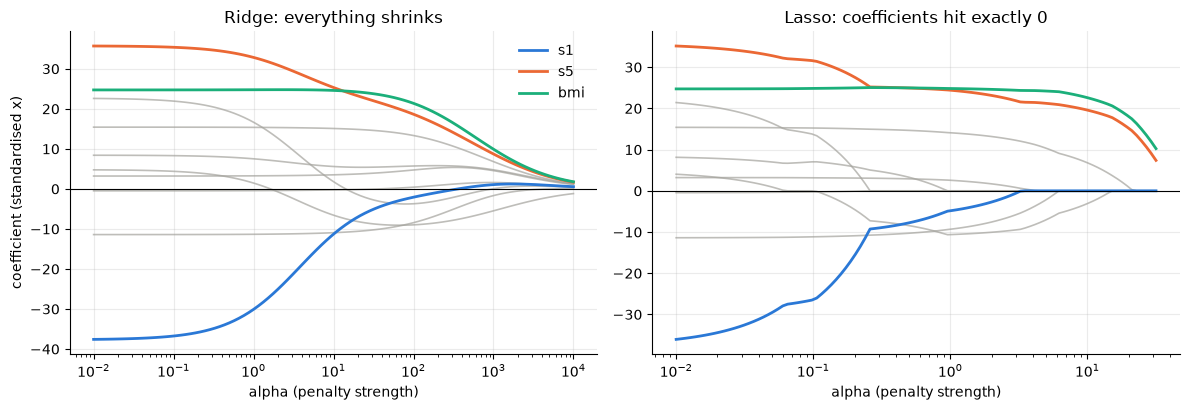

In [5]:
from sklearn.linear_model import Ridge, Lasso

Xz = StandardScaler().fit_transform(X)
alphas = np.logspace(-2, 4, 100)
ridge_path = np.array([Ridge(alpha=a).fit(Xz, y).coef_ for a in alphas])
lasso_alphas = np.logspace(-2, 1.5, 100)
lasso_path = np.array([Lasso(alpha=a).fit(Xz, y).coef_ for a in lasso_alphas])

top = np.argsort(-np.abs(ridge_path[0]))[:3]          # highlight the 3 largest
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, a, path, title in [(axes[0], alphas, ridge_path, "Ridge: everything shrinks"),
                           (axes[1], lasso_alphas, lasso_path, "Lasso: coefficients hit exactly 0")]:
    for j in range(path.shape[1]):
        if j not in top:
            ax.plot(a, path[:, j], color=GREY, lw=1.2, alpha=0.7)
    for k, j in enumerate(top):
        ax.plot(a, path[:, j], color=PALETTE[k], label=X.columns[j])
    ax.set_xscale("log"); ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("alpha (penalty strength)"); ax.set_title(title)
axes[0].set_ylabel("coefficient (standardised x)"); axes[0].legend()
plt.tight_layout()
plt.show()

## 4. Lasso as feature selection

In [6]:
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED)).fit(X, y)
coefs = pd.Series(lasso[-1].coef_, index=X.columns)
print(f"chosen alpha = {lasso[-1].alpha_:.3f}; kept {(coefs != 0).sum()} of {len(coefs)} features")
coefs.sort_values()

chosen alpha = 0.079; kept 9 of 10 features


s1    -27.0854
sex   -11.2250
age    -0.3089
s3     -0.0000
s6      3.1790
s4      6.8350
s2     14.3862
bp     15.2713
bmi    24.8168
s5     31.8650
dtype: float64

Caveat: with correlated features Lasso picks one somewhat arbitrarily and drops the rest; the chosen set can change between bootstrap samples. Use Elastic Net if you want correlated features kept together.

## 5. Head-to-head with cross-validation

In [7]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(10, shuffle=True, random_state=SEED)
rows = []
for name, m in {
    "OLS": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED)),
    "ElasticNet": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .5, .9], cv=5, random_state=SEED)),
}.items():
    s = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append((name, s.mean(), s.std()))
pd.DataFrame(rows, columns=["model", "CV RMSE", "sd"]).set_index("model")

,CV RMSE,sd
model,,
OLS,54.8606,3.7376
Ridge,55.0394,3.7493
Lasso,54.9654,3.6472
ElasticNet,54.8714,3.6465


With 442 rows and only 10 features, OLS is already fine; the differences are well inside one standard deviation. Regularisation matters when $p$ is large relative to $n$, or when the signal is weak.

## 6. Non-linearity with linear models

"Linear" means linear in the *coefficients*. You can add transformed features (logs, squares, interactions, splines) and still fit with Ridge.

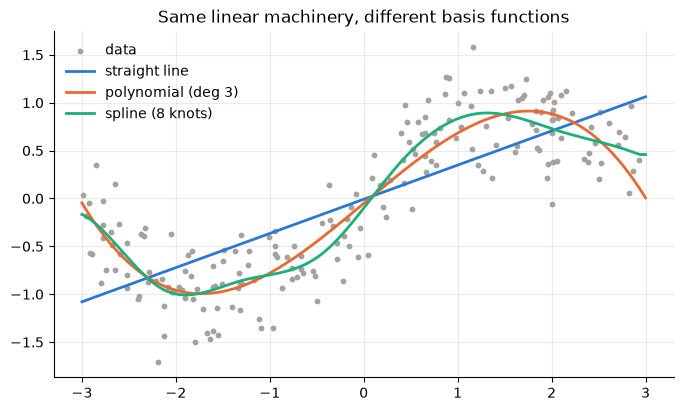

In [8]:
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer

x1 = np.sort(rng.uniform(-3, 3, 200))
y1 = np.sin(x1) + 0.3 * rng.normal(size=200)
grid = np.linspace(-3, 3, 300)[:, None]

fig, ax = plt.subplots()
ax.scatter(x1, y1, s=10, color=GREY, label="data")
for k, (name, m) in enumerate({
    "straight line": LinearRegression(),
    "polynomial (deg 3)": make_pipeline(PolynomialFeatures(3), Ridge(1e-3)),
    "spline (8 knots)": make_pipeline(SplineTransformer(n_knots=8), Ridge(1e-3)),
}.items()):
    ax.plot(grid, m.fit(x1[:, None], y1).predict(grid), color=PALETTE[k], label=name)
ax.legend(); ax.set_title("Same linear machinery, different basis functions")
plt.show()

## 7. Weak signals: shrink the predictions

When the signal is weak (e.g. predicting returns), even a correctly-signed model can **lose to predicting zero** on MSE if its predictions are too large.
Scale the predictions by $c$. The MSE gain over predicting zero (for a mean-zero target) is

$$\text{gain}(c) = 2c\,\mathrm{Cov}(\hat y, y) - c^2\,\mathrm{Var}(\hat y) \quad\Rightarrow\quad c^* = \frac{\mathrm{Cov}(\hat y, y)}{\mathrm{Var}(\hat y)}$$

i.e. $c^*$ is the slope from regressing $y$ on $\hat y$ **out of sample**. A slope below 1 means the predictions are overconfident. Ridge shrinks coefficients; this shrinks predictions directly. Estimate $c^*$ on validation folds, never on the test set.

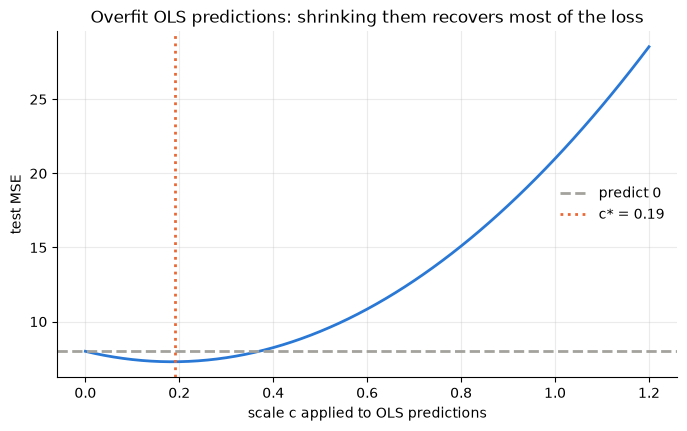

In [9]:
ols_pred = LinearRegression().fit(Xs_tr, ys_tr).predict(Xs_te)
cs = np.linspace(0, 1.2, 61)
mse = [np.mean((ys_te - c * ols_pred) ** 2) for c in cs]
c_star = np.cov(ols_pred, ys_te)[0, 1] / np.var(ols_pred)

fig, ax = plt.subplots()
ax.plot(cs, mse, color=PALETTE[0])
ax.axhline(np.mean(ys_te ** 2), color=GREY, ls="--", label="predict 0")
ax.axvline(c_star, color=PALETTE[1], ls=":", label=f"c* = {c_star:.2f}")
ax.set_xlabel("scale c applied to OLS predictions"); ax.set_ylabel("test MSE"); ax.legend()
ax.set_title("Overfit OLS predictions: shrinking them recovers most of the loss")
plt.show()

## Takeaways
- Start with **Ridge in a pipeline with `StandardScaler`**. It's rarely a bad first model.
- Use statsmodels for inference (p-values, CIs) and sklearn for prediction.
- Lasso when you believe few features matter; Elastic Net when features are correlated.
- Add non-linearity via features (splines, interactions), or move to trees/boosting (notebooks 05–08).
- With weak signals, check the out-of-sample slope of $y$ on $\hat y$ and shrink if it's below 1.